<a href="https://colab.research.google.com/github/halynazhabchyk/intro_to_pytorch/blob/main/NLP_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ПРАКТИЧНА РОБОТА 3: КОНЦЕПЦІЯ ДИСТРИБУТИВНОЇ
СЕМАНТИКИ. РЕАЛІЗАЦІЯ МОДЕЛІ WORD2VEC

Мета роботи: Ознайомитися з концепцією дистрибутивної семантики та
принципами роботи моделі Word2Vec. Реалізувати та навчити цю модель із
використанням бібліотеки PyTorch.

Дистрибутивна семантика – це підхід в обробці природної мови (NLP)
та лінгвістиці, який базується на аналізі використання слів у контекстах для
визначення їхнього значення. Основна ідея полягає в тому, що значення
слова визначається через його вживання в текстах.

Щоб розпочати роботу, спершу імпортуємо необхідні бібліотеки

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
import torch.nn.functional as F

Завантажуємо дані

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving nyt-ingredients-snapshot-2015.csv to nyt-ingredients-snapshot-2015.csv


In [ ]:
data = pd.read_csv("nyt-ingredients-snapshot-2015.csv", encoding="utf-8")
sentences_all = data['input'].dropna().tolist()

len(sentences_all)

179063

Оскільки датасет є великим за своїм обсягом для зручності обчислень беремо тільки 25%

In [ ]:
np.random.seed(42)
np.random.shuffle(sentences_all)
half_index = len(sentences_all) // 4
sentences = sentences_all[:half_index]
len(sentences)

44765

Розділяємо на текстовий та тренувальни набір

In [ ]:

split_idx = int(0.7*len(sentences))
train_sentences = sentences[:split_idx]
val_sentences = sentences[split_idx:]


In [ ]:
len(train_sentences)

31335

In [ ]:
len(val_sentences)

13430

Для токенізації та векторизації текстів застосовуємо вбудований TfidfVectorizer

In [ ]:
np.random.seed(42)
np.random.shuffle(sentences_all)
stop_words = ["a", "an", "the", "and", "or", "but", "if", "then", "else",
              "for", "on", "in", "at", "by", "with", "from", "to", "of", "this", "that",
              "these", "those", "is", "are", "was", "were",
              "be", "been", "being", "have", "has", "had", "do", "does",
              "did", "not", "no", "yes", "it", "its", "as", "can", "will",
              "just", "so", "such", "up", "down", "out", "over", "under"]

stop_words = [w.lower() for w in stop_words]
# Параметри векторизаторів
vectorizer_params = {
    "token_pattern": r'\b[a-zA-Z0-9]{4,}\b',
    "max_df": 0.1,
    "min_df": 1,
    "max_features": 20000,
    "stop_words": stop_words

}

vectorizer = TfidfVectorizer(**vectorizer_params)
feature_matrix_train = vectorizer.fit_transform(train_sentences)
feature_matrix_test = vectorizer.fit_transform(val_sentences)

Окремо для зручності створюємо функцію токенізації вручну

In [ ]:
vocab = vectorizer.vocabulary_

def tokenize_sentences(sentences, vocab):
    tokenized = []
    for sent in sentences:
        words = [w for w in sent.lower().split() if w in vocab]
        tokenized.append(words)
    return tokenized

tokenized_train = tokenize_sentences(train_sentences, vocab)
tokenized_val = tokenize_sentences(val_sentences, vocab)
word_counts = np.zeros(len(vocab))
for sent in tokenized_train:
    for w in sent:
        idx = vocab[w]
        word_counts[idx] += 1

len(word_counts), len(vocab)

(2466, 2466)

Візуалізуємо розподіл довжин речень до токенізації

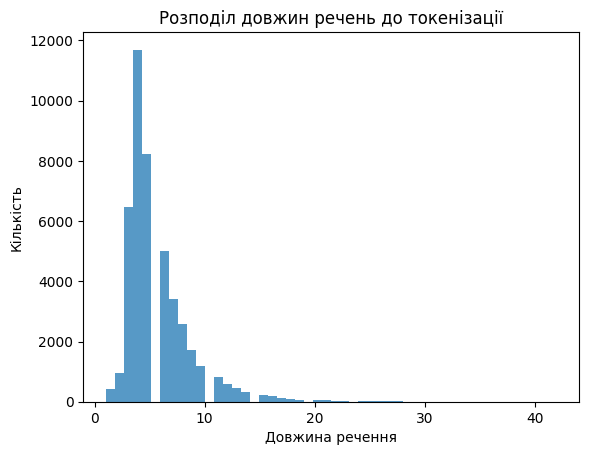

In [ ]:
sentence_lengths = [len(sentence.split()) for sentence in sentences]
plt.hist(sentence_lengths, bins=50, alpha=0.75)
plt.title("Розподіл довжин речень до токенізації")
plt.xlabel("Довжина речення")
plt.ylabel("Кількість")
plt.show()

Візуалізуємо розподіл довжин речень після токенізації

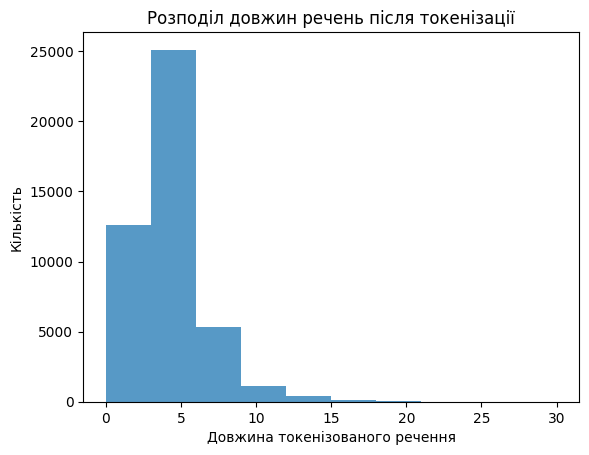

In [ ]:

tokenizer = vectorizer.build_analyzer()
tokenized_sentences = [tokenizer(doc) for doc in sentences]

tokenized_lengths = [len(sentence) for sentence in tokenized_sentences]
plt.hist(tokenized_lengths, bins=10, alpha=0.75)
plt.title("Розподіл довжин речень після токенізації")
plt.xlabel("Довжина токенізованого речення")
plt.ylabel("Кількість")
plt.show()


Розподіл частот слів має вигляд

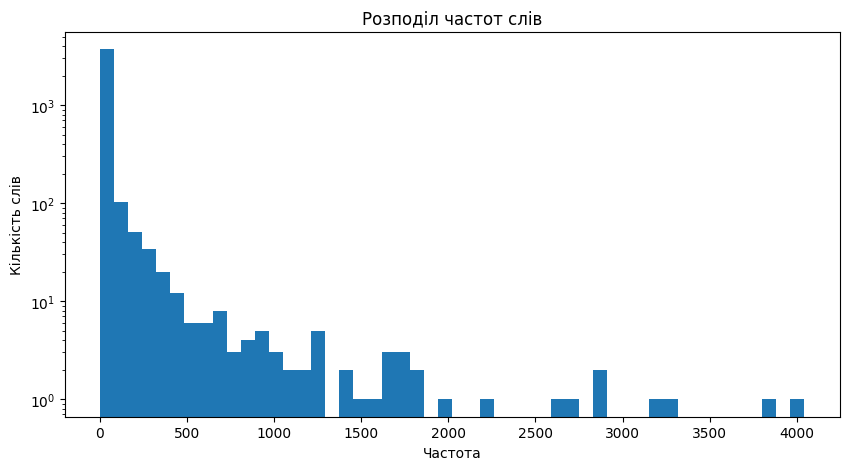

In [ ]:
count_vectorizer = CountVectorizer(**vectorizer_params)
X_counts = count_vectorizer.fit_transform(sentences)

word_counts = np.asarray(X_counts.sum(axis=0)).ravel()
vocab_size = len(count_vectorizer.vocabulary_)


plt.figure(figsize=(10, 5))
plt.hist(word_counts, bins=50, log=True)
plt.xlabel("Частота")
plt.ylabel("Кількість слів")
plt.title("Розподіл частот слів")
plt.show()


Пернйдемо до формування PyTorch Dataset та Dataloader, розбиття
набору даних на тренувальний та валідаційний набори.

Створюємо клас, що реалізує  обробку текстових даних для PyTorch. Його мета –
підготувати речення у вигляді тензорів із фіксованою довжиною, що
спрощує роботу з батчами.

In [ ]:
class PaddedSequenceDataset(Dataset):
    def __init__(self, sentences, vocab, max_len=20):
        self.sentences = sentences
        self.vocab = vocab
        self.max_len = max_len

    def __len__(self):
        return len(self.sentences)

    def __getitem__(self, idx):
        sentence = self.sentences[idx]
        # кодування словами в індекси
        encoded = [self.vocab.get(word, 0) for word in sentence]
        encoded = encoded[:self.max_len]
        if len(encoded) < self.max_len:
            encoded += [0] * (self.max_len - len(encoded))
        return torch.tensor(encoded, dtype=torch.long)

Застосовуємо клас для створення тренувального та валідаційного датасетів

In [ ]:
MAX_SENTENCE_LEN = 20
train_dataset = PaddedSequenceDataset(train_sentences, vocab, max_len=MAX_SENTENCE_LEN)
val_dataset = PaddedSequenceDataset(val_sentences, vocab, max_len=MAX_SENTENCE_LEN)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64)


Створюємо клас SkipGramModel - це архітектура моделі Word2Vec. Вона використовує рухоме контекстне вікно фіксованої ширини, в межах якого центральне слово застосовується для передбачення сусідніх (контекстних) слів. Для кожного слова існують два векторні представлення: одне як центрального слова (матриця W), інше — як контекстного слова (матриця D). Під час навчання модель максимізує ймовірність правильного передбачення контексту за центральним словом. У результаті слова, які часто з’являються разом у тексті, отримують подібні векторні представлення у спільному просторовому просторі.

In [ ]:
class SkipGramModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, pad_idx=0):
        super().__init__()

        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.center_embeddings = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.context_embeddings = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.init_weights(self.center_embeddings)
        self.init_weights(self.context_embeddings)

    def init_weights(self, embedding_layer):
        bound = 1.0 / (embedding_layer.embedding_dim ** 0.5)
        nn.init.uniform_(embedding_layer.weight, -bound, bound)
        embedding_layer.weight.data = F.normalize(embedding_layer.weight.data, dim=1)

    def create_context_mask(self, sentence_length, window_size):
        mask = torch.zeros((sentence_length, sentence_length))
        for i in range(sentence_length):
            start = max(0, i - window_size // 2)
            end = min(sentence_length, i + window_size // 2 + 1)
            mask[i, start:end] = 1
        return mask

Даний клас використовується для створення векторних уявлень слів (ембеддінгів).
Модель навчається передбачати зв’язок між центральним словом (center
word) і словами з його контексту (context words)

Функція create_context_mask створює квадратну матрицю, яка
визначає контекстні вікна для кожного токена в реченні. Ця матриця
використовується для позначення того, які токе

Реалізуємо глобальну функцію для підбору негативних прикладів для навчання(негативного семплінгу). Це
дозволяє моделі вчитися відрізняти реальні контекстні слова від
випадкових.

In [ ]:
def sample_negative_words(vocab_size, batch_size, num_negatives, word_freq):
    probabilities = np.array(word_freq, dtype=np.float64)
    probabilities = probabilities / probabilities.sum()
    negative_samples = np.random.choice(
        np.arange(vocab_size),
        size=(batch_size, num_negatives),
        p=probabilities
    )
    return torch.tensor(negative_samples, dtype=torch.long)


Далі реалізуємо клас SkipGramTrainer, що успадковує SkipGramModel і реалізує тренувальну логіку.

In [ ]:
class SkipGramTrainer:
    def __init__(self, vocab_size, embedding_dim, pad_idx=0, num_negatives=5, word_freq=None, window_size=2):
        self.model = SkipGramModel(vocab_size, embedding_dim, pad_idx)
        self.num_negatives = num_negatives
        self.vocab_size = vocab_size
        self.word_freq = word_freq
        self.window_size = window_size

    def forward(self, sentence_tensor):
        if sentence_tensor.dim() == 1:
            sentence_tensor = sentence_tensor.unsqueeze(0)
        batch_size, sentence_length = sentence_tensor.shape

        mask = self.model.create_context_mask(sentence_length, self.window_size).to(sentence_tensor.device)

        centers, contexts = [], []
        for b in range(batch_size):
            for i in range(sentence_length):
                for j in range(sentence_length):
                    if mask[i, j] > 0 and i != j:
                        centers.append(sentence_tensor[b, i].item())
                        contexts.append(sentence_tensor[b, j].item())

        if len(centers) == 0:
            return torch.tensor(0.0, device=sentence_tensor.device, requires_grad=True)

        center_words = torch.tensor(centers, dtype=torch.long, device=sentence_tensor.device)
        context_words = torch.tensor(contexts, dtype=torch.long, device=sentence_tensor.device)

        # Позитивний loss
        center_vecs = self.model.center_embeddings(center_words)
        context_vecs = self.model.context_embeddings(context_words)
        pos_score = torch.sum(center_vecs * context_vecs, dim=1)
        pos_loss = -torch.log(torch.sigmoid(pos_score) + 1e-9).mean()

        # Негативний loss
        negative_words = sample_negative_words(
            vocab_size=self.vocab_size,
            batch_size=center_words.size(0),
            num_negatives=self.num_negatives,
            word_freq=self.word_freq
        ).to(center_words.device)

        neg_vecs = self.model.context_embeddings(negative_words)  # (N, K, D)
        neg_score = torch.bmm(neg_vecs, center_vecs.unsqueeze(2)).squeeze(2)
        neg_loss = -torch.log(torch.sigmoid(-neg_score) + 1e-9).mean()

        return pos_loss + neg_loss

Далі реалізуємо функцію для тестування та тренування моделі.

In [ ]:
from tqdm.auto import tqdm
import torch
import torch.optim as optim

def train_eval_loop(trainer, train_loader, val_loader, num_epochs=5, lr=0.01, lr_decay=0.5, patience=2, device="cpu"):
    trainer.model.to(device)
    optimizer = optim.Adam(trainer.model.parameters(), lr=lr)
    train_losses, val_losses = [], []

    best_val_loss = float("inf")
    patience_counter = 0

    for epoch in range(1, num_epochs + 1):
        # -------- TRAIN --------
        trainer.model.train()
        total_train_loss = 0.0
        for batch in tqdm(train_loader, desc=f"Epoch {epoch} [Train]"):
            batch = batch.to(device)  # батч речень
            optimizer.zero_grad()
            loss = trainer.forward(batch)  # forward з одним аргументом
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()

        train_loss = total_train_loss / len(train_loader)
        train_losses.append(train_loss)

        trainer.model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for batch in tqdm(val_loader, desc=f"Epoch {epoch} [Val]"):
                batch = batch.to(device)
                loss = trainer.forward(batch)
                total_val_loss += loss.item()

        val_loss = total_val_loss / len(val_loader)
        val_losses.append(val_loss)

        print(f"Epoch {epoch}/{num_epochs} — Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                lr *= lr_decay
                for param_group in optimizer.param_groups:
                    param_group['lr'] = lr
                patience_counter = 0

    return train_losses, val_losses

Результат:

In [ ]:
trainer = SkipGramTrainer(
    vocab_size=len(vocab),
    embedding_dim=100,
    pad_idx=vocab.get("<PAD>", 0),
    num_negatives=5,
    word_freq=word_counts,
    window_size=2
)

device = "cuda" if torch.cuda.is_available() else "cpu"

train_losses, val_losses = train_eval_loop(
    trainer,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=5,
    lr=0.01,
    device=device
)

Epoch 1 [Train]:   0%|          | 0/490 [00:00<?, ?it/s]

Epoch 1 [Val]:   0%|          | 0/210 [00:00<?, ?it/s]

Epoch 1/5 — Train Loss: 0.7302, Val Loss: 0.7005


Epoch 2 [Train]:   0%|          | 0/490 [00:00<?, ?it/s]

Epoch 2 [Val]:   0%|          | 0/210 [00:00<?, ?it/s]

...

Epoch 4 [Val]:   0%|          | 0/210 [00:00<?, ?it/s]

Epoch 4/5 — Train Loss: 0.6983, Val Loss: 0.6983


Epoch 5 [Train]:   0%|          | 0/490 [00:00<?, ?it/s]

Epoch 5 [Val]:   0%|          | 0/210 [00:00<?, ?it/s]

Epoch 5/5 — Train Loss: 0.6982, Val Loss: 0.6982


Створюємо функцію для побудови кривих втрат

In [ ]:
import matplotlib.pyplot as plt

def plot_loss_curves(train_losses, val_losses):
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(10, 6))
    plt.plot(epochs, train_losses, label='Train Loss')
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.title('Loss Curves')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

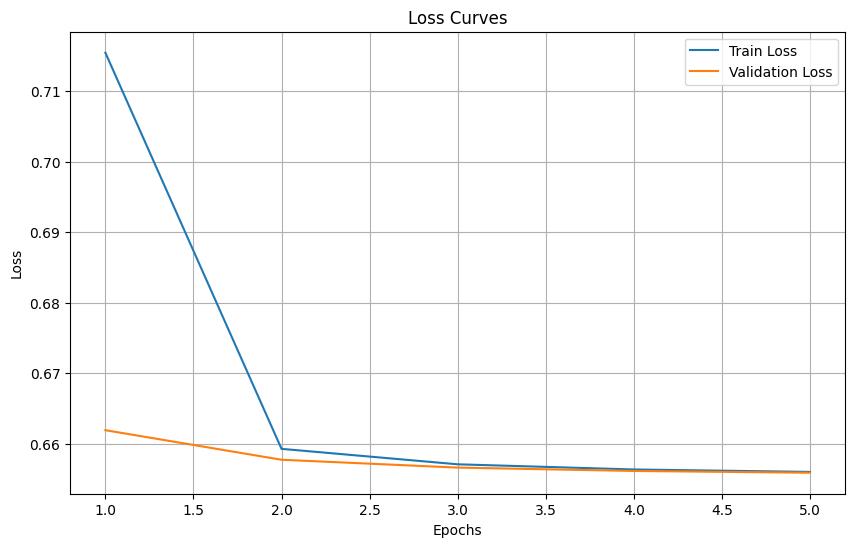

In [ ]:
plot_loss_curves(train_losses, val_losses)

Далі змінимо

Розмір контекстного вікна (window_size).
Кількість негативних прикладів (num_negatives).
Розмір ембеддінгів (embedding_dim).





Розмір контекстного вікна (window_size) - це радіум слів поряд, які має враховувати модель. При більших значеннях модель вчиться краще узагальнювати.

Кількість негативних прикладів (num_negatives)- кількість слів, що навмисно не є контекстом центрового слова, використовується для негативного семплінгу.
Якщо взяти мале число (1-3), то можна пришвидшити навчання, проте вбудування можуть бути більш шумними. Якщо використати більше число, то модель краще відокремлюватиме слова.



Розмір ембеддінгів (embedding_dim) - це кількість чисел у векторі слова (розмірність простору ембеддінгів).

Якщо він малий, то навчання швидше, менше використовується пам’яті, але ембеддінги менш виразні, не всі семантичні відмінності зможуть бути закодовані.

При більших значеннях ембеддінги багатші, захоплюють більше семантичних і синтаксичних нюансів.


Спробуємо зменшити дані показники та збільшити кількість епох

In [ ]:
trainer_min = SkipGramTrainer(
    vocab_size=len(vocab),
    embedding_dim=50,
    pad_idx=vocab.get("<PAD>", 0),
    num_negatives=3,
    word_freq=word_counts,
    window_size=2
)

device = "cuda" if torch.cuda.is_available() else "cpu"

train_losses, val_losses = train_eval_loop(
    trainer_min,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=7,
    lr=0.01,
    device=device
)

Epoch 1 [Train]:   0%|          | 0/245 [00:00<?, ?it/s]

Epoch 1 [Val]:   0%|          | 0/105 [00:00<?, ?it/s]

Epoch 1/10 — Train Loss: 0.7668, Val Loss: 0.6939


Epoch 2 [Train]:   0%|          | 0/245 [00:00<?, ?it/s]

Epoch 2 [Val]:   0%|          | 0/105 [00:00<?, ?it/s]

...

Epoch 9 [Val]:   0%|          | 0/105 [00:00<?, ?it/s]

Epoch 9/10 — Train Loss: 0.6828, Val Loss: 0.6828


Epoch 10 [Train]:   0%|          | 0/245 [00:00<?, ?it/s]

Epoch 10 [Val]:   0%|          | 0/105 [00:00<?, ?it/s]

Epoch 10/10 — Train Loss: 0.6828, Val Loss: 0.6827


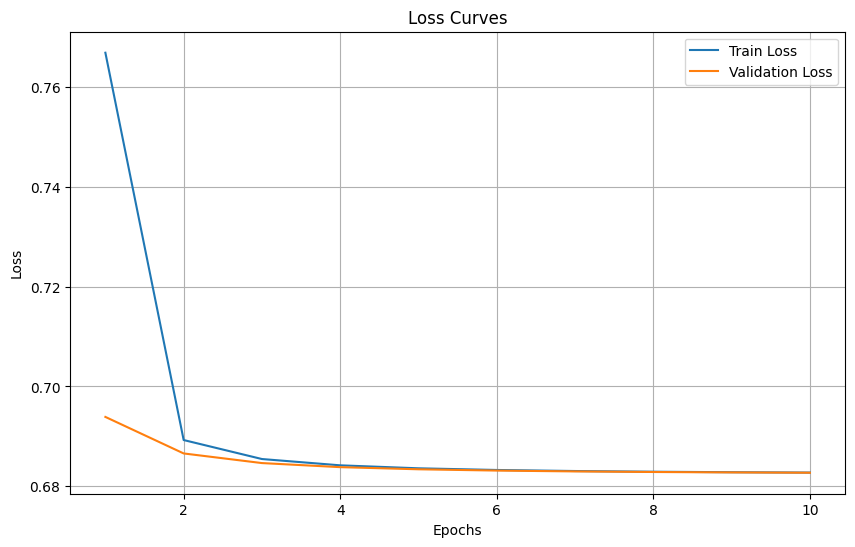

In [ ]:
plot_loss_curves(train_losses, val_losses)

Бачимо що втрати є більшими порівняно з попередніми результатами. Збіжність досягається слабко через гірше узагальнення через зменшення показників. Окрім того також варто зменшити  лернінг рейт для кращої збіжності.

In [ ]:
trainer_max = SkipGramTrainer(
    vocab_size=len(vocab),
    embedding_dim=150,
    pad_idx=vocab.get("<PAD>", 0),
    num_negatives=7,
    word_freq=word_counts,
    window_size=4
)

device = "cuda" if torch.cuda.is_available() else "cpu"

train_losses, val_losses = train_eval_loop(
    trainer_max,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=10,
    lr=0.01,
    device=device
)

Epoch 1 [Train]:   0%|          | 0/245 [00:00<?, ?it/s]

Epoch 1 [Val]:   0%|          | 0/105 [00:00<?, ?it/s]

Epoch 1/10 — Train Loss: 0.7868, Val Loss: 0.7434


Epoch 2 [Train]:   0%|          | 0/245 [00:00<?, ?it/s]

Epoch 2 [Val]:   0%|          | 0/105 [00:00<?, ?it/s]

...

Epoch 9 [Val]:   0%|          | 0/105 [00:00<?, ?it/s]

Epoch 9/10 — Train Loss: 0.7389, Val Loss: 0.7389


Epoch 10 [Train]:   0%|          | 0/245 [00:00<?, ?it/s]

Epoch 10 [Val]:   0%|          | 0/105 [00:00<?, ?it/s]

Epoch 10/10 — Train Loss: 0.7389, Val Loss: 0.7388


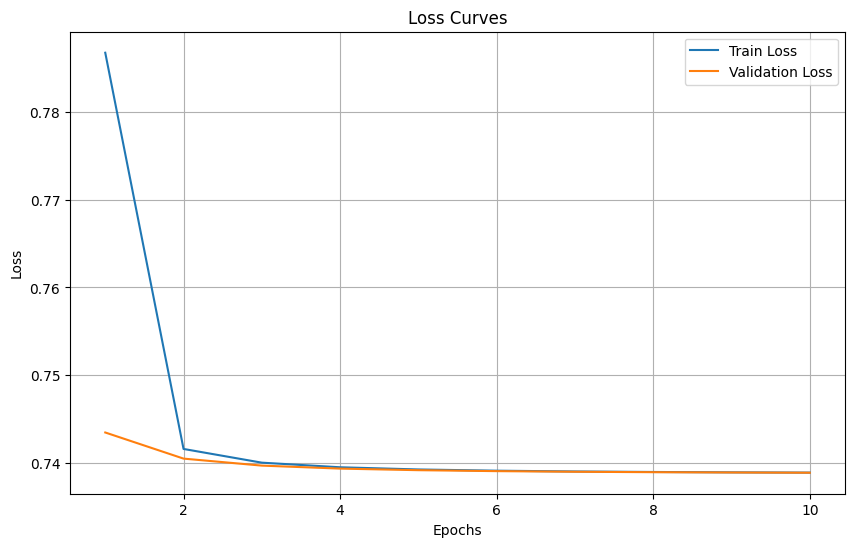

In [ ]:
plot_loss_curves(train_losses, val_losses)

Бачимо, що збіжність досі низька тому ми маємо ще зменшити швидеість навчання.

Завантажуємо першу модель:

In [ ]:
torch.save(trainer.model.state_dict(), "skipgram_model.pth")
print("Модель успішно збережена.")

Модель успішно збережена.


Далі реалізовуємо клас для дослідження ембеддінгів

In [ ]:

class WordEmbeddingsExplorer:
    def __init__(self, embeddings, vocab):
        """
        Ініціалізація класу для аналізу ембеддінгів.
        :param embeddings: Прямокутна матриця [vocab_size, embedding_dim].
        :param vocab: Словник {токен: індекс}.
        """
        self.embeddings = embeddings
        self.vocab = vocab
        self.token_to_index = {token: idx for token, idx in vocab.items()}
        self.index_to_token = {idx: token for token, idx in vocab.items()}

        # Нормалізація ембеддінгів
        norms = np.linalg.norm(self.embeddings, axis=1, keepdims=True)
        self.embeddings = self.embeddings / (norms + 1e-9)

    def most_similar_by_vector(self, vector, top_n=5):
        """
        Знаходить слова, найбільш схожі на заданий вектор.
        :param vector: Вектор [embedding_dim].
        :param top_n: Кількість найближчих слів.
        :return: Список пар (слово, схожість).
        """
        similarities = np.dot(self.embeddings, vector)
        closest_indices = np.argsort(similarities)[::-1][:top_n]
        return [(self.index_to_token[idx], similarities[idx]) for idx in closest_indices]

    def most_similar(self, word, top_n=5):
        """
        Знаходить слова, найбільш схожі на задане слово.
        :param word: Слово у текстовому форматі.
        :param top_n: Кількість найближчих слів.
        :return: Список пар (слово, схожість).
        """
        if word not in self.token_to_index:
            return f"Слово '{word}' відсутнє у словнику."
        word_idx = self.token_to_index[word]
        return self.most_similar_by_vector(self.embeddings[word_idx], top_n=top_n)

vocab_size = len(vocab)
embedding_dim = 100
pad_idx = vocab.get("<PAD>", 0)

loaded_model = SkipGramModel(vocab_size, embedding_dim, pad_idx)
loaded_model.load_state_dict(torch.load("skipgram_model.pth", map_location="cpu"))

# Отримання центрових ембеддінгів
center_embeddings = loaded_model.center_embeddings.weight.detach().cpu().numpy()

# Нормалізація ембеддінгів
norms = np.linalg.norm(center_embeddings, axis=1, keepdims=True)
center_embeddings = center_embeddings / (norms + 1e-9)

# Створення об'єкта для аналізу ембеддінгів
explorer = WordEmbeddingsExplorer(center_embeddings, vocab)



Перевіряємо слова на схожість

In [ ]:
words = ["cheese", "cake", "coffee"]
for word in words:
  print(f"Схожі слова до '{word}':")
  print(explorer.most_similar(word, top_n=5))

Схожі слова до 'cheese':
[('cheese', np.float32(0.99999994)), ('fong', np.float32(0.36721647)), ('escarole', np.float32(0.34865347)), ('brooklyn', np.float32(0.3374983)), ('patties', np.float32(0.30326957))]
Схожі слова до 'cake':
[('cake', np.float32(0.99999994)), ('canola', np.float32(0.34888312)), ('cantaloupe', np.float32(0.34449536)), ('vodka', np.float32(0.3425313)), ('chili', np.float32(0.33690125))]
Схожі слова до 'coffee':
[('coffee', np.float32(1.0)), ('ribbons', np.float32(0.3277909)), ('caviar', np.float32(0.31816596)), ('gaeta', np.float32(0.30171525)), ('petals', np.float32(0.29423028))]


Результати показують, що модель знаходить слова з певною схожістю, але семантична якість ембеддінгів поки що невисока.

Для слова “cheese” найближчі слова не є чітко пов’язаними за змістом. Наприклад, “escarole” і “patties” ще можна пов’язати з їжею, але “brooklyn” не має прямого семантичного зв’язку. Це означає, що модель частково вловлює тематику (харчові продукти), але простір ембеддінгів недостатньо структурований.

Для “cake” ситуація схожа: “canola”, “cantaloupe”, “chili” — це продукти харчування, але зв’язок не дуже точний. Для “coffee” слова “caviar” або “petals” не є природно близькими за значенням, що свідчить про слабку контекстну узгодженість.

Далі реалізуємо функції для пошуків семантичної аналогії та візуалізація перших num_words ембеддінгів.

In [ ]:

from sklearn.manifold import TSNE

def visualize_embeddings(embeddings, vocab, num_words=100):
    """
    Візуалізує перші num_words ембеддінгів.
    :param embeddings: Матриця ембеддінгів [vocab_size, embedding_dim].
    :param vocab: Словник {токен: індекс}.
    :param num_words: Кількість слів для візуалізації.
    """
    tsne = TSNE(n_components=2, random_state=42, init='random')
    reduced_embeddings = tsne.fit_transform(embeddings[:num_words])

    plt.figure(figsize=(12, 8))
    for idx, word in enumerate(list(vocab.keys())[:num_words]):
        x, y = reduced_embeddings[idx]
        plt.scatter(x, y)
        plt.annotate(word, (x, y), fontsize=9, alpha=0.7)
    plt.title("Візуалізація ембеддінгів слів")
    plt.show()


def visualize_selected_words(embeddings, vocab, selected_words):
    """
    Візуалізує обрані слова на площині з використанням TSNE.
    :param embeddings: Матриця ембеддінгів [vocab_size, embedding_dim].
    :param vocab: Словник {токен: індекс}.
    :param selected_words: Список обраних слів для візуалізації.
    """
    indices = []
    filtered_words = []
    for word in selected_words:
        if word in vocab:
            indices.append(vocab[word])
            filtered_words.append(word)
        else:
            print(f"Слово '{word}' відсутнє у словнику.")

    if len(indices) == 0:
        print("Немає слів для візуалізації.")
        return

    selected_embeddings = embeddings[indices]

    tsne = TSNE(n_components=2, random_state=42, init='random')
    reduced_embeddings = tsne.fit_transform(selected_embeddings)

    plt.figure(figsize=(10, 7))
    for idx, word in enumerate(filtered_words):
        x, y = reduced_embeddings[idx]
        plt.scatter(x, y, label=word)
        plt.annotate(word, (x, y), fontsize=10, alpha=0.7)
    plt.title("Візуалізація обраних слів")
    plt.legend()
    plt.show()

def analogy(word_a, word_b, word_c, explorer, top_n=5):
    """
    Розв'язує семантичну пропорцію: A відноситься до B, як C до ?
    :param word_a: Слово A.
    :param word_b: Слово B.
    :param word_c: Слово C.
    :param explorer: Об'єкт WordEmbeddingsExplorer.
    :param top_n: Кількість результатів.
    :return: Список слів, схожих до пропорції.
    """
    for word in [word_a, word_b, word_c]:
        if word not in explorer.token_to_index:
            return f"Слово '{word}' відсутнє у словнику."

    vector_a = explorer.embeddings[explorer.token_to_index[word_a]]
    vector_b = explorer.embeddings[explorer.token_to_index[word_b]]
    vector_c = explorer.embeddings[explorer.token_to_index[word_c]]

    result_vector = vector_b - vector_a + vector_c
    return explorer.most_similar_by_vector(result_vector, top_n=top_n)


# Приклад семантичної пропорції
print("Пропорція: king : man :: queen : ?")
print(analogy("king", "man", "qeen", explorer, top_n=5))

Пропорція: king : man :: queen : ?
Слово 'man' відсутнє у словнику.


У випадку аналогії «king : man :: queen : ?» модель не змогла виконати обчислення, оскільки слово “man” відсутнє у словнику. Це означає, що відповідний токен не зустрічався в навчальному корпусі або був відфільтрований під час побудови словника.

In [ ]:
# Приклад семантичної пропорції
print("Пропорція: cake : cacao :: cheese : ?")
print(analogy("cake", "cacao", "cheese", explorer, top_n=5))

Пропорція: cake : cacao :: cheese : ?
[('cheese', np.float32(0.9938334)), ('cacao', np.float32(0.7931572)), ('raspberries', np.float32(0.52796376)), ('west', np.float32(0.458373)), ('fidencio', np.float32(0.45210847))]


Логічно очікувати щось на кшталт milk, dairy або rennet, тобто інгредієнт або джерело походження сиру. Проте модель повертає “cacao” та “raspberries”, що свідчить про слабку семантичну узгодженість векторного простору. Вона, ймовірно, вловлює загальну категорію “їжа”, а не конкретний відношеннєвий зв’язок (продукт → інгредієнт).

Дана ситуація у нас спостерігається через взяття невеликого корпусу з метою пришвидшення обчислень.
Skip-gram моделі потребують великої кількості тексту для формування стабільних семантичних відношень. Окрім того, embedding_dim невеликий, модель не має достатньої просторової “місткості” для кодування складних відношень.

Створимо модель для всього корпусу

In [ ]:
np.random.seed(42)
np.random.shuffle(sentences_all)
split_idx = int(0.7*len(sentences_all))
train_sentences = sentences_all[:split_idx]
val_sentences = sentences_all[split_idx:]


stop_words = ["a", "an", "the", "and", "or", "but", "if", "then", "else",
              "for", "on", "in", "at", "by", "with", "from", "to", "of", "this", "that",
              "these", "those", "is", "are", "was", "were",
              "be", "been", "being", "have", "has", "had", "do", "does",
              "did", "not", "no", "yes", "it", "its", "as", "can", "will",
              "just", "so", "such", "up", "down", "out", "over", "under"]

stop_words = [w.lower() for w in stop_words]
# Параметри векторизаторів
vectorizer_params = {
    "token_pattern": r'\b[a-zA-Z0-9]{4,}\b',
    "max_df": 0.1,
    "min_df": 1,
    "max_features": 20000,
    "stop_words": stop_words

}

vectorizer = TfidfVectorizer(**vectorizer_params)
feature_matrix_train = vectorizer.fit_transform(train_sentences)
feature_matrix_test = vectorizer.fit_transform(val_sentences)

In [ ]:
vocab = vectorizer.vocabulary_

def tokenize_sentences(sentences, vocab):
    tokenized = []
    for sent in sentences:
        words = [w for w in sent.lower().split() if w in vocab]
        tokenized.append(words)
    return tokenized

tokenized_train = tokenize_sentences(train_sentences, vocab)
tokenized_val = tokenize_sentences(val_sentences, vocab)
word_counts = np.zeros(len(vocab))
for sent in tokenized_train:
    for w in sent:
        idx = vocab[w]
        word_counts[idx] += 1

len(word_counts), len(vocab)

(4270, 4270)

In [ ]:
MAX_SENTENCE_LEN = 20
train_dataset = PaddedSequenceDataset(train_sentences, vocab, max_len=MAX_SENTENCE_LEN)
val_dataset = PaddedSequenceDataset(val_sentences, vocab, max_len=MAX_SENTENCE_LEN)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64)


In [ ]:
# ===============================
trainer_all = SkipGramTrainer(
    vocab_size=len(vocab),
    embedding_dim=100,
    pad_idx=vocab.get("<PAD>", 0),
    num_negatives=5,
    word_freq=word_counts,
    window_size=3
)

device = "cuda" if torch.cuda.is_available() else "cpu"

train_losses, val_losses = train_eval_loop(
    trainer_all,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=5,
    lr=0.003,
    device=device
)

Epoch 1 [Train]:   0%|          | 0/1959 [00:00<?, ?it/s]

Epoch 1 [Val]:   0%|          | 0/840 [00:00<?, ?it/s]

Epoch 1/5 — Train Loss: 0.7296, Val Loss: 0.7018


Epoch 2 [Train]:   0%|          | 0/1959 [00:00<?, ?it/s]

Epoch 2 [Val]:   0%|          | 0/840 [00:00<?, ?it/s]

...

Epoch 4 [Val]:   0%|          | 0/840 [00:00<?, ?it/s]

Epoch 4/5 — Train Loss: 0.7002, Val Loss: 0.7002


Epoch 5 [Train]:   0%|          | 0/1959 [00:00<?, ?it/s]

Epoch 5 [Val]:   0%|          | 0/840 [00:00<?, ?it/s]

Epoch 5/5 — Train Loss: 0.7002, Val Loss: 0.7002


Нам необхідно зменшити швидкість навчання для досягнення кращої збіжності

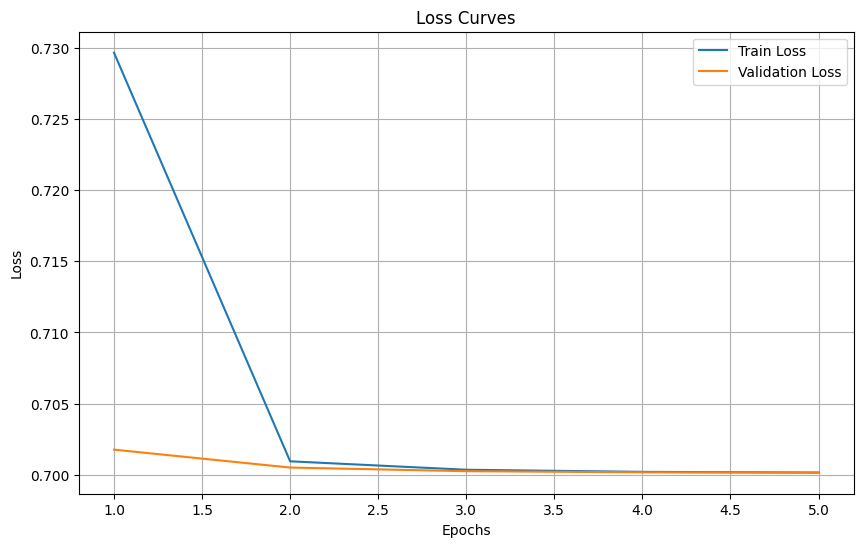

In [ ]:
plot_loss_curves(train_losses, val_losses)

Завантажимо модель

In [ ]:
torch.save(trainer_all.model.state_dict(), "skipgram_model_all.pth")
print("Модель успішно збережена.")

Модель успішно збережена.


In [ ]:

class WordEmbeddingsExplorer:
    def __init__(self, embeddings, vocab):
        """
        Ініціалізація класу для аналізу ембеддінгів.
        :param embeddings: Прямокутна матриця [vocab_size, embedding_dim].
        :param vocab: Словник {токен: індекс}.
        """
        self.embeddings = embeddings
        self.vocab = vocab
        self.token_to_index = {token: idx for token, idx in vocab.items()}
        self.index_to_token = {idx: token for token, idx in vocab.items()}

        # Нормалізація ембеддінгів
        norms = np.linalg.norm(self.embeddings, axis=1, keepdims=True)
        self.embeddings = self.embeddings / (norms + 1e-9)

    def most_similar_by_vector(self, vector, top_n=5):
        """
        Знаходить слова, найбільш схожі на заданий вектор.
        :param vector: Вектор [embedding_dim].
        :param top_n: Кількість найближчих слів.
        :return: Список пар (слово, схожість).
        """
        similarities = np.dot(self.embeddings, vector)
        closest_indices = np.argsort(similarities)[::-1][:top_n]
        return [(self.index_to_token[idx], similarities[idx]) for idx in closest_indices]

    def most_similar(self, word, top_n=5):
        """
        Знаходить слова, найбільш схожі на задане слово.
        :param word: Слово у текстовому форматі.
        :param top_n: Кількість найближчих слів.
        :return: Список пар (слово, схожість).
        """
        if word not in self.token_to_index:
            return f"Слово '{word}' відсутнє у словнику."
        word_idx = self.token_to_index[word]
        return self.most_similar_by_vector(self.embeddings[word_idx], top_n=top_n)

vocab_size = len(vocab)
embedding_dim = 100
pad_idx = vocab.get("<PAD>", 0)

loaded_model = SkipGramModel(vocab_size, embedding_dim, pad_idx)
loaded_model.load_state_dict(torch.load("skipgram_model_all.pth", map_location="cpu"))

# Отримання центрових ембеддінгів
center_embeddings = loaded_model.center_embeddings.weight.detach().cpu().numpy()

# Нормалізація ембеддінгів
norms = np.linalg.norm(center_embeddings, axis=1, keepdims=True)
center_embeddings = center_embeddings / (norms + 1e-9)

# Створення об'єкта для аналізу ембеддінгів
explorer = WordEmbeddingsExplorer(center_embeddings, vocab)



In [ ]:

from sklearn.manifold import TSNE

def visualize_embeddings(embeddings, vocab, num_words=100):
    """
    Візуалізує перші num_words ембеддінгів.
    :param embeddings: Матриця ембеддінгів [vocab_size, embedding_dim].
    :param vocab: Словник {токен: індекс}.
    :param num_words: Кількість слів для візуалізації.
    """
    tsne = TSNE(n_components=2, random_state=42, init='random')
    reduced_embeddings = tsne.fit_transform(embeddings[:num_words])

    plt.figure(figsize=(12, 8))
    for idx, word in enumerate(list(vocab.keys())[:num_words]):
        x, y = reduced_embeddings[idx]
        plt.scatter(x, y)
        plt.annotate(word, (x, y), fontsize=9, alpha=0.7)
    plt.title("Візуалізація ембеддінгів слів")
    plt.show()


def visualize_selected_words(embeddings, vocab, selected_words):
    """
    Візуалізує обрані слова на площині з використанням TSNE.
    :param embeddings: Матриця ембеддінгів [vocab_size, embedding_dim].
    :param vocab: Словник {токен: індекс}.
    :param selected_words: Список обраних слів для візуалізації.
    """
    indices = []
    filtered_words = []
    for word in selected_words:
        if word in vocab:
            indices.append(vocab[word])
            filtered_words.append(word)
        else:
            print(f"Слово '{word}' відсутнє у словнику.")

    if len(indices) == 0:
        print("Немає слів для візуалізації.")
        return

    selected_embeddings = embeddings[indices]

    tsne = TSNE(n_components=2, random_state=42, init='random')
    reduced_embeddings = tsne.fit_transform(selected_embeddings)

    plt.figure(figsize=(10, 7))
    for idx, word in enumerate(filtered_words):
        x, y = reduced_embeddings[idx]
        plt.scatter(x, y, label=word)
        plt.annotate(word, (x, y), fontsize=10, alpha=0.7)
    plt.title("Візуалізація обраних слів")
    plt.legend()
    plt.show()

def analogy(word_a, word_b, word_c, explorer, top_n=5):
    """
    Розв'язує семантичну пропорцію: A відноситься до B, як C до ?
    :param word_a: Слово A.
    :param word_b: Слово B.
    :param word_c: Слово C.
    :param explorer: Об'єкт WordEmbeddingsExplorer.
    :param top_n: Кількість результатів.
    :return: Список слів, схожих до пропорції.
    """
    for word in [word_a, word_b, word_c]:
        if word not in explorer.token_to_index:
            return f"Слово '{word}' відсутнє у словнику."

    vector_a = explorer.embeddings[explorer.token_to_index[word_a]]
    vector_b = explorer.embeddings[explorer.token_to_index[word_b]]
    vector_c = explorer.embeddings[explorer.token_to_index[word_c]]

    result_vector = vector_b - vector_a + vector_c
    return explorer.most_similar_by_vector(result_vector, top_n=top_n)



Перевіримо на схожість

In [ ]:
words = ["wine", "cake", "grape"]
for word in words:
  print(f"Схожі слова до '{word}':")
  print(explorer.most_similar(word, top_n=5))

Схожі слова до 'wine':
[('wine', np.float32(1.0000002)), ('sourdough', np.float32(0.37555623)), ('eastern', np.float32(0.3529161)), ('filets', np.float32(0.3439106)), ('grain', np.float32(0.3287065))]
Схожі слова до 'cake':
[('cake', np.float32(1.0)), ('satsumas', np.float32(0.37979072)), ('african', np.float32(0.30707029)), ('sometimes', np.float32(0.28774256)), ('fourth', np.float32(0.2875072))]
Схожі слова до 'grape':
[('grape', np.float32(0.99999994)), ('rendered', np.float32(0.4004887)), ('remember', np.float32(0.38886294)), ('broiling', np.float32(0.34230912)), ('hens', np.float32(0.3352967))]


Перевіримо семантичну пропорцію


In [ ]:
# Приклад семантичної пропорції
print("Пропорція: saffron : spice :: basil : ?")
print(analogy("saffron", "spice", "basil", explorer, top_n=10))

Пропорція: saffron : spice :: basil : ?
[('basil', np.float32(1.0629343)), ('spice', np.float32(1.0057867)), ('kecap', np.float32(0.5914105)), ('shards', np.float32(0.5497798)), ('8478', np.float32(0.5168142)), ('cavatappi', np.float32(0.4761084)), ('cheesecloth', np.float32(0.47588184)), ('tunsalted', np.float32(0.47110024)), ('maine', np.float32(0.46703982)), ('milagro', np.float32(0.46166134))]


З огляду на перевірки, модель все ще має погані результати з схожоісті та семантичної пропорції. Це можна пояснити недостатнім навчанням і підбором правильних гіперпараметрів. На жаль, з точки зору обчислювальної та часової складності виконання донавчання є досить затратним. Тому даний варіант моделі є суто демонстративним.